In [ ]:
from pathlib import Path

import pandas as pd
import matplotlib.pyplot as plt

# Support running from the repository root or this notebook's directory.
data_path = Path("data/dirty/real_votes.csv")
if not data_path.exists():
    data_path = Path("../../data/dirty/real_votes.csv")

real_votes = pd.read_csv(data_path)


In [ ]:
# Count every CSV row, including any missing proposal types.
proposal_type_counts = (
    real_votes["proposal_type"]
    .fillna("(Missing)")
    .value_counts()
    .rename_axis("proposal_type")
    .reset_index(name="count")
)

print(f"{len(proposal_type_counts)} proposal types across {len(real_votes):,} vote records")
display(proposal_type_counts)


24 proposal types across 13,757 vote records


,proposal_type,count
0,DIRECTOR_ELECTION,6645
1,AUDITOR,1099
2,FIN_STATEMENTS,888
3,DISCHARGE,759
4,DIVIDEND,652
5,OTHER_MGMT,646
6,SAY_ON_PAY,550
7,ROUTINE,453
8,DIRECTOR_PAY,382
9,EQUITY_PLAN,375


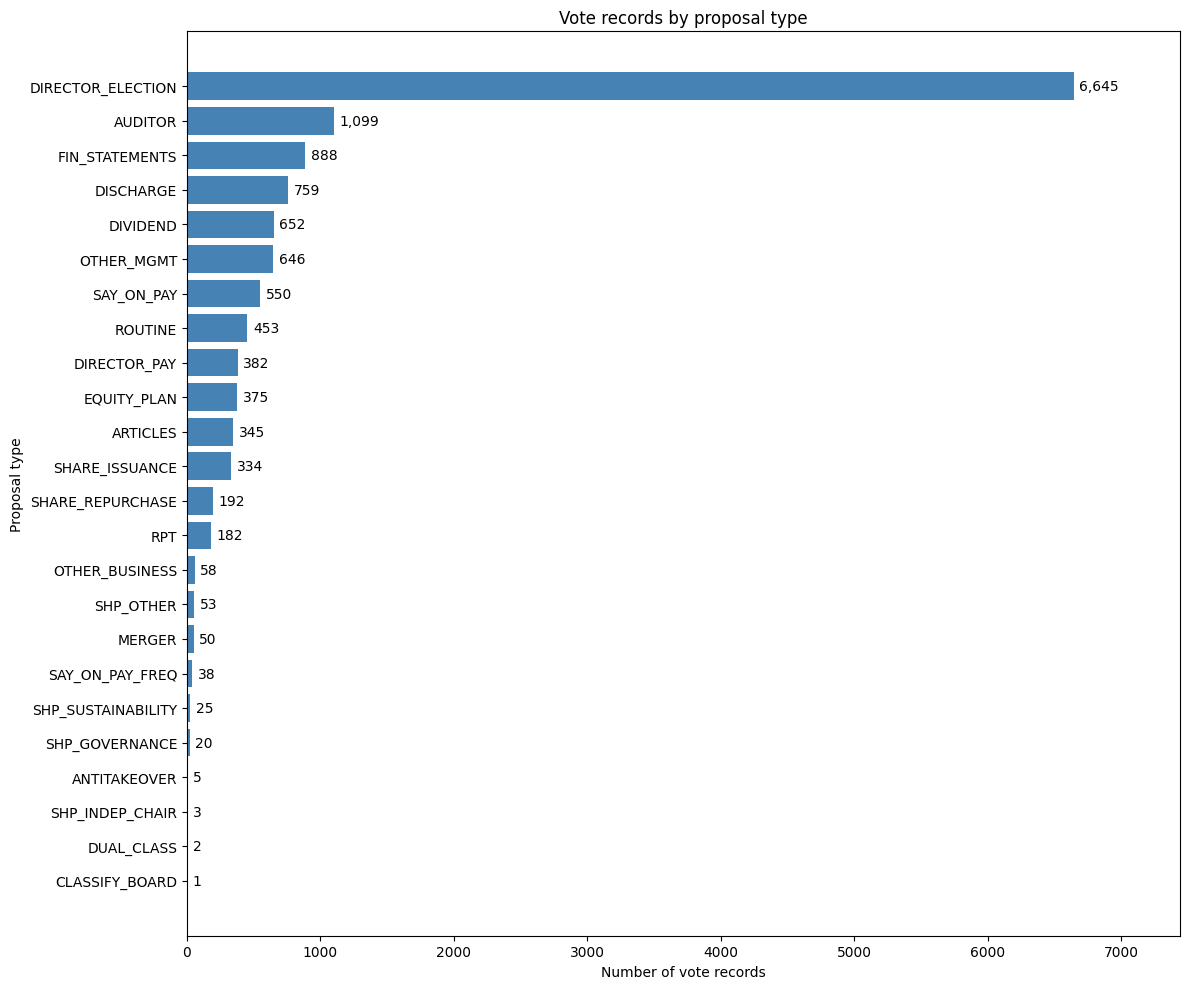

In [ ]:
fig, ax = plt.subplots(figsize=(12, 10))
bars = ax.barh(
    proposal_type_counts["proposal_type"],
    proposal_type_counts["count"],
    color="steelblue",
)
ax.invert_yaxis()
ax.bar_label(bars, labels=[f"{count:,}" for count in proposal_type_counts["count"]], padding=4)
ax.set_title("Vote records by proposal type")
ax.set_xlabel("Number of vote records")
ax.set_ylabel("Proposal type")
ax.set_xlim(0, proposal_type_counts["count"].max() * 1.12)
fig.tight_layout()
plt.show()


In [ ]:
# Count every CSV row, including any missing countries.
country_counts = (
    real_votes["country"]
    .fillna("(Missing)")
    .value_counts()
    .rename_axis("country")
    .reset_index(name="count")
)

print(f"{len(country_counts)} countries across {len(real_votes):,} vote records")
display(country_counts)


37 countries across 13,757 vote records


,country,count
0,Japan,2403
1,United States,2376
2,China,988
3,United Kingdom,965
4,Sweden,778
5,India,643
6,Germany,573
7,Switzerland,561
8,Cayman Islands,491
9,South Korea,488


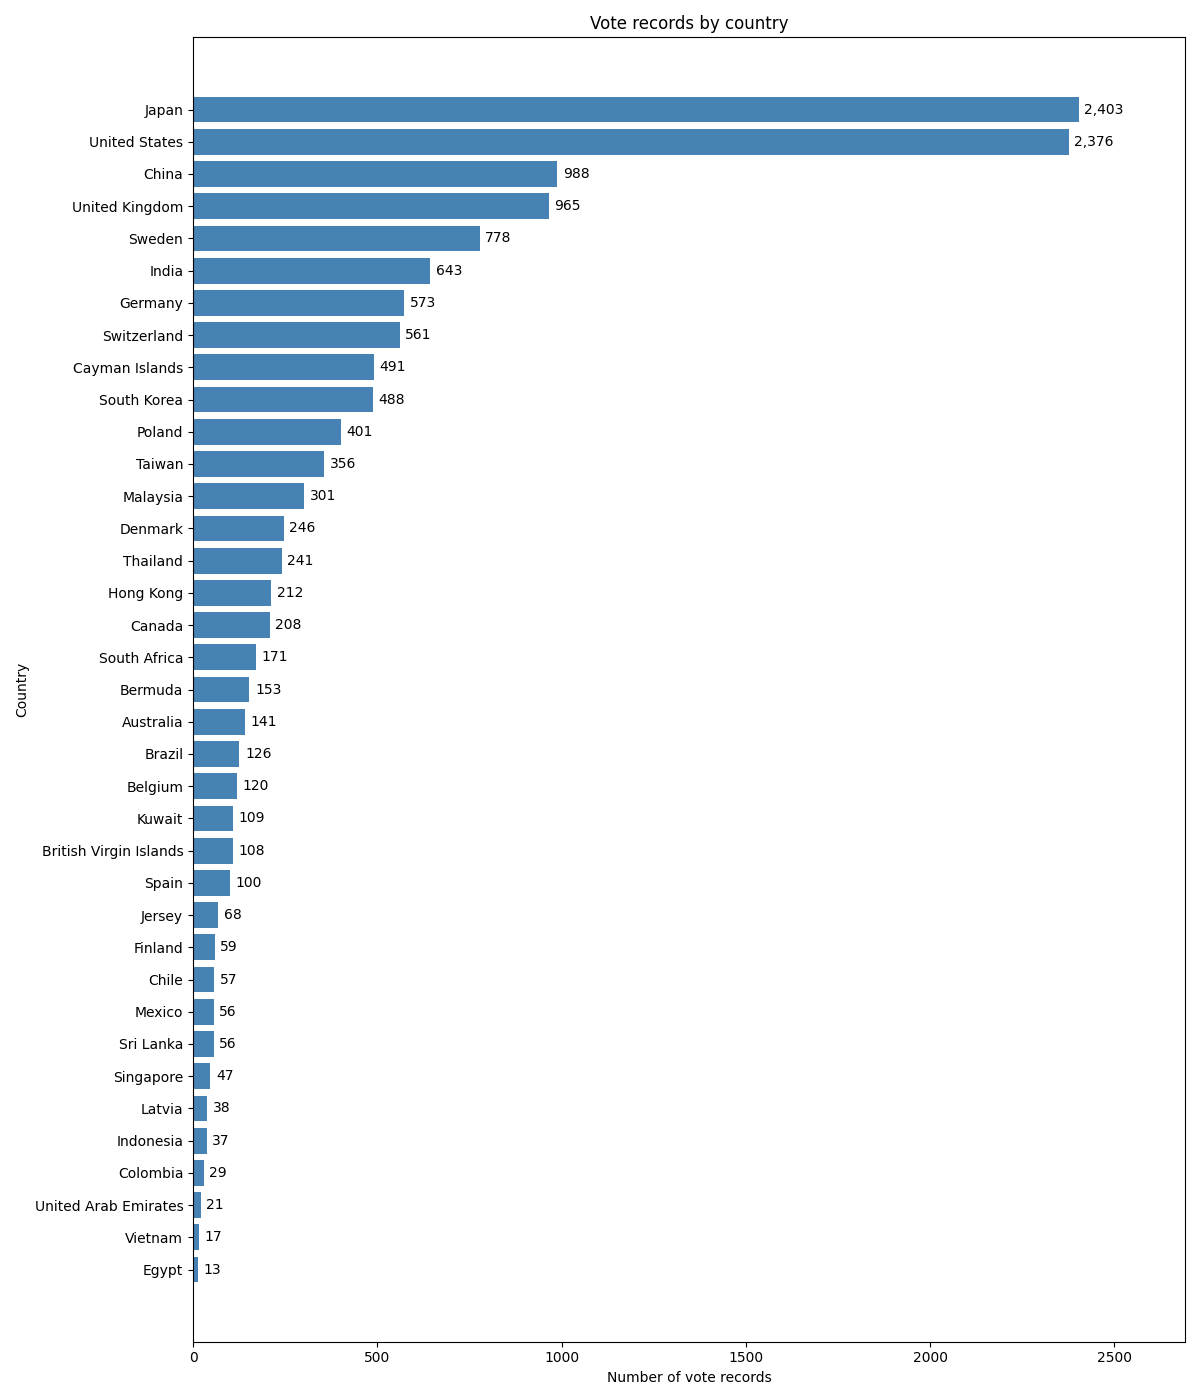

In [ ]:
fig, ax = plt.subplots(figsize=(12, 14))
bars = ax.barh(
    country_counts["country"],
    country_counts["count"],
    color="steelblue",
)
ax.invert_yaxis()
ax.bar_label(bars, labels=[f"{count:,}" for count in country_counts["count"]], padding=4)
ax.set_title("Vote records by country")
ax.set_xlabel("Number of vote records")
ax.set_ylabel("Country")
ax.set_xlim(0, country_counts["count"].max() * 1.12)
fig.tight_layout()
plt.show()
